In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("Mall_Customers.csv")
print(df.head())
print(df.info())
print(df.isnull().sum())


   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
CustomerID                0
Gender                 

In [4]:
from sklearn.preprocessing import StandardScaler
X = df[['Annual Income (k$)',
'Spending Score (1-100)']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

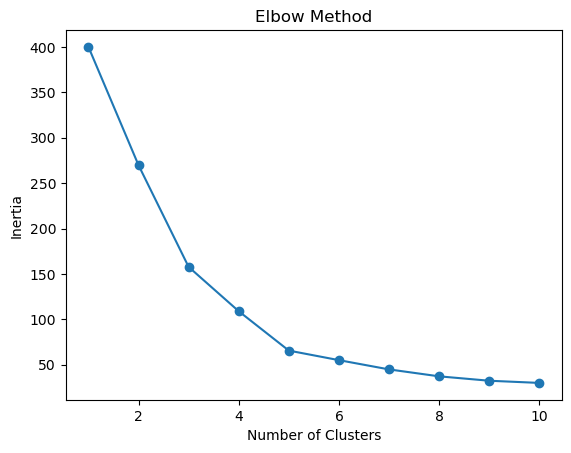

In [9]:
from sklearn.cluster import KMeans

inertias = []
for k in range(1,11):
    model = KMeans(
        n_clusters=k,
        random_state = 42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)
plt.plot(range(1,11), inertias, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


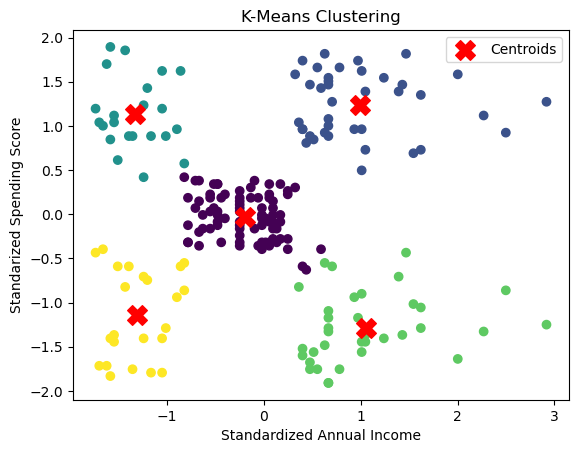

In [11]:
k =5
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=kmeans_labels,
    cmap='viridis'
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    c='red',
    marker='X',
    s=200,
    label='Centroids'
)


plt.xlabel("Standardized Annual Income")
plt.ylabel("Standarized Spending Score")
plt.title("K-Means Clustering")
plt.legend()
plt.show()



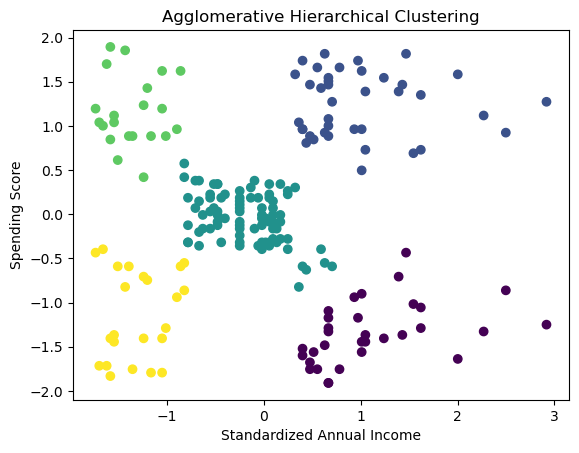

In [12]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage='ward'
)

hierarchical_labels = (
    hierarchical.fit_predict(X_scaled)
)

plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=hierarchical_labels,
    cmap='viridis'
)

plt.xlabel("Standardized Annual Income")
plt.ylabel("Spending Score")
plt.title("Agglomerative Hierarchical Clustering")
plt.show()


    

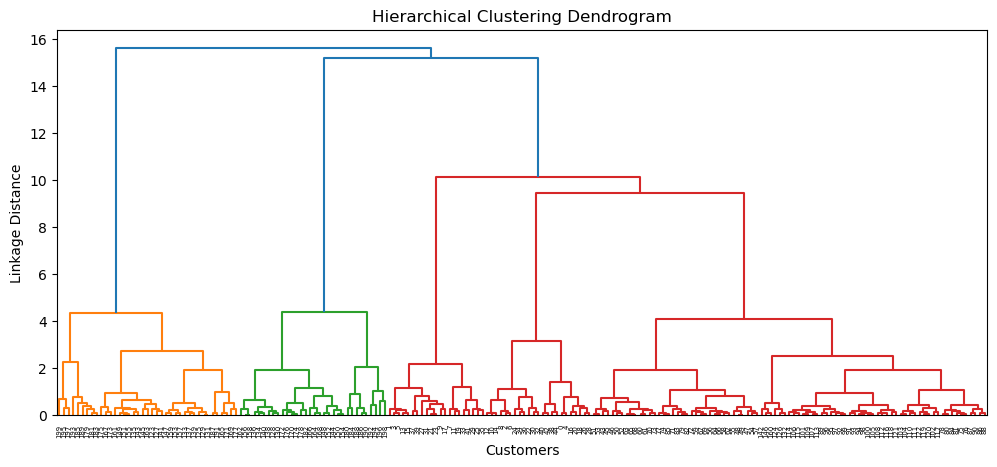

In [13]:
from scipy.cluster.hierarchy import (
    linkage, dendrogram
)

linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(12,5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Linkage Distance")
plt.show()

In [20]:
from sklearn.metrics import silhouette_score
import numpy as np
kmeans_sil = silhouette_score(
    X_scaled,kmeans_labels
)

hierarchical_sil = silhouette_score(
    X_scaled, hierarchical_labels
)

def calculate_inertia(X, labels):
    total = 0
    for cluster in np.unique(labels):
points = X[labels == cluster]
centroid = points.mean(axis=0)
total += np.sum(
(points - centroid)**2
)
return total

results = pd.DataFrame({
"Algorithm":[
"K-Means","Agglomerative"
],
"Inertia": [
kmeans.inertia_,
calculate_inertia(
X_scaled,hierarchical_labels
)
],
"Silhouette Score": [
kmeans_sil, hierarchical_sil
]
})

print(results)

AttributeError: 'numpy.ndarray' object has no attribute 'means'